# What does a cat-vs-dog model look at?

Kaimei's demo model `cats-dogs-photos` is a MobileNetV2 with a cat/dog head, trained on the
Oxford-IIIT Pet photos. It gets 99% of the test photos right, but *what has it learned to look
at*? This notebook asks the Kaimei API to explain a few photos and draws the answers exactly as
the dashboard's **Explain** tab does: the same pictures, the same colours, the same sentences.

**How to read the figures**

- **Heatmap**: red and orange glow where the photo is evidence *for* the class (the redder, the
  stronger); blue where it is evidence *against* it. The glow stays see-through, so you can check
  what lies underneath. The white outline encloses the **focus region**, the smallest part of the
  photo that holds half of the evidence.
- **Numbered badges**: the strongest regions, marked on the heatmap and listed with the same
  numbers in the chart on the right: first the regions *for* the class (orange), then the ones
  *against* it (blue). Names like "centre 3" are only positions; the number is what to follow.
- **Spotlight**: the photo itself, dimmed everywhere except the focus region.
- **Evidence check** (bottom row): the model is asked again with the focus region blurred away,
  and with *only* the focus region left sharp. If the answer collapses without the region, the
  region matters.
- The **summary** above each figure says the same in two or three sentences.

## Setup

```bash
pip install "kaimei[images]" matplotlib
```

Create an API key in the dashboard and set `KAIMEI_API_KEY`. For a local API, also set
`KAIMEI_BASE_URL` (for example `http://localhost:8000`); otherwise `https://api.kaimei.ai` is used.

Run the notebook from the `examples` folder so it finds `photos/`.

In [1]:
import functools
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from kaimei import Kaimei
from kaimei.images import explanation_summary, image_feature, load_image, plot_explanation, render_explanation

MODEL = "cats-dogs-photos"
PHOTOS = Path("photos") if Path("photos").is_dir() else Path("examples/photos")
plt.rcParams["figure.dpi"] = 100
try:  # photos compress far better as JPEG, which keeps the saved notebook small
    from matplotlib_inline.backend_inline import set_matplotlib_formats

    set_matplotlib_formats("jpeg", pil_kwargs={"quality": 85})
except ImportError:  # not running under Jupyter's inline backend: keep the defaults
    pass


def require_key() -> None:
    """Every API cell calls this first, so a missing key fails with one clear line."""
    if not os.environ.get("KAIMEI_API_KEY"):
        raise RuntimeError("Set KAIMEI_API_KEY to an API key from the dashboard before running this cell.")


client = Kaimei(
    api_key=os.environ.get("KAIMEI_API_KEY"),
    base_url=os.environ.get("KAIMEI_BASE_URL", "https://api.kaimei.ai"),
    timeout=600,  # LIME runs the model a few hundred times
)
print("key set:", bool(os.environ.get("KAIMEI_API_KEY")))

key set: True


## The model and the example photos

In [2]:
require_key()
model = client.models.retrieve(MODEL)
feature = image_feature(model)
print(model.name, "|", model.task, "| labels:", model.outputs["labels"],
      "| input:", f"{feature['height']}x{feature['width']}x{feature.get('channels', 3)}")

Cats vs dogs (photos) | binary_classification | labels: ['cat', 'dog'] | input: 224x224x3


Six photos from the dataset's **test split** (never seen in training) plus a composite with a cat
on the left and a dog on the right. `load_image` reads each one the way the model expects: the
shorter side scaled to 224 and the middle cropped, like torchvision's `Resize` + `CenterCrop`.
The dashboard offers the same seven photos as clickable examples.

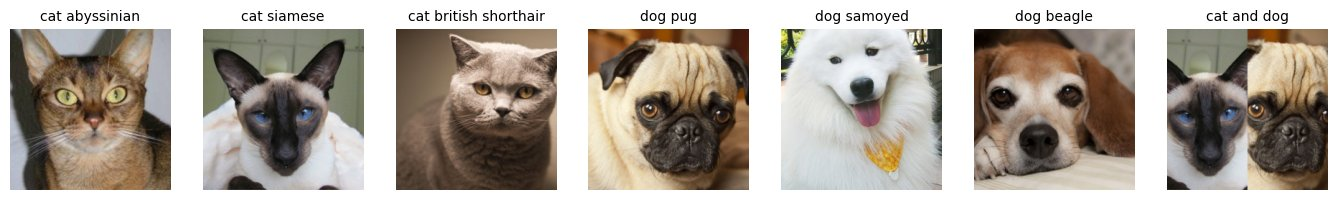

In [3]:
NAMES = ["cat_abyssinian", "cat_siamese", "cat_british_shorthair", "dog_pug", "dog_samoyed", "dog_beagle"]
pixels = {name: load_image(PHOTOS / f"{name}.jpg", model=model) for name in NAMES + ["cat_and_dog"]}

fig, axes = plt.subplots(1, 7, figsize=(17, 2.9))
for ax, name in zip(axes, NAMES + ["cat_and_dog"]):
    ax.imshow(np.asarray(pixels[name]))
    ax.set_title(name.replace("_", " "), fontsize=10)
    ax.set_axis_off()
plt.show()

## Where does the model look?

One API call per photo, with **Grad-CAM**: a single pass through the network that follows the
gradient of the answer back to the last layer that still has a picture-like layout (7×7 cells
over the photo). `plot_explanation` draws the dashboard's view of the answer.

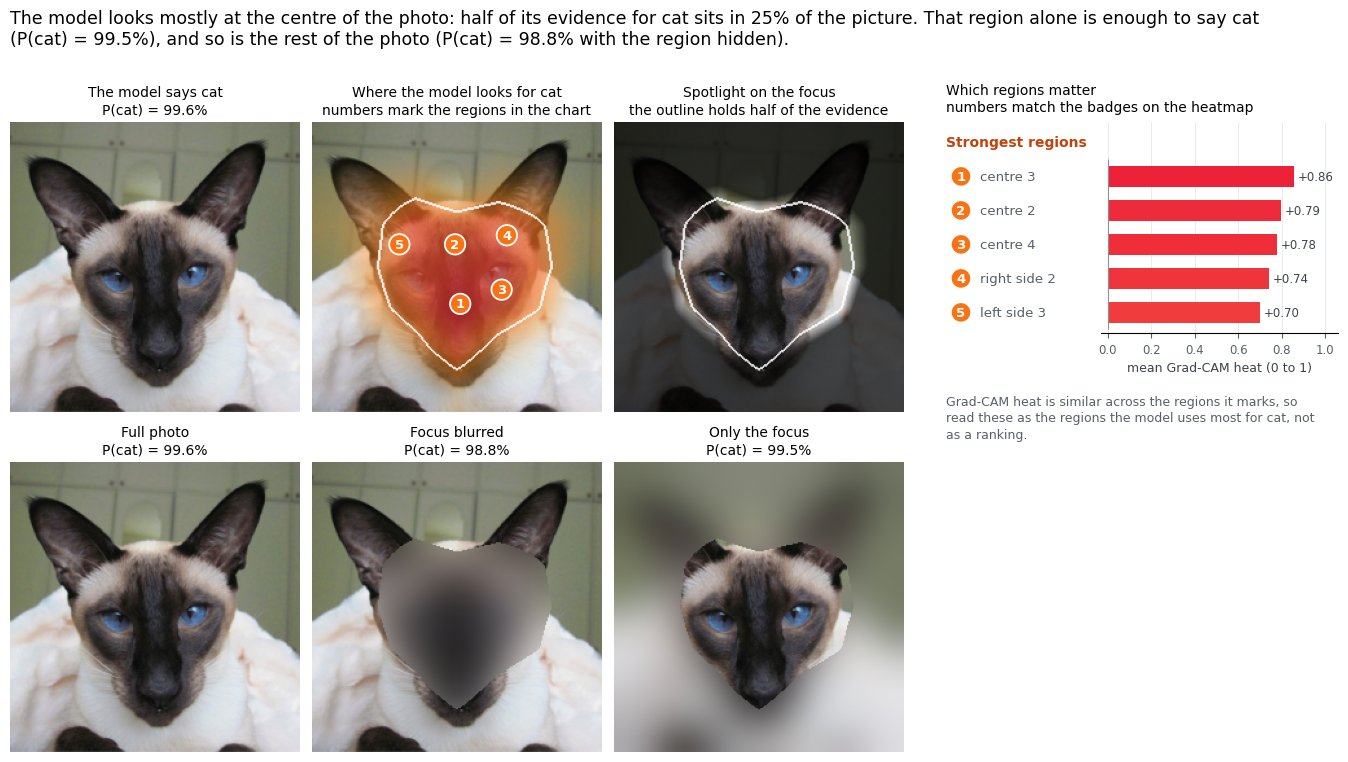

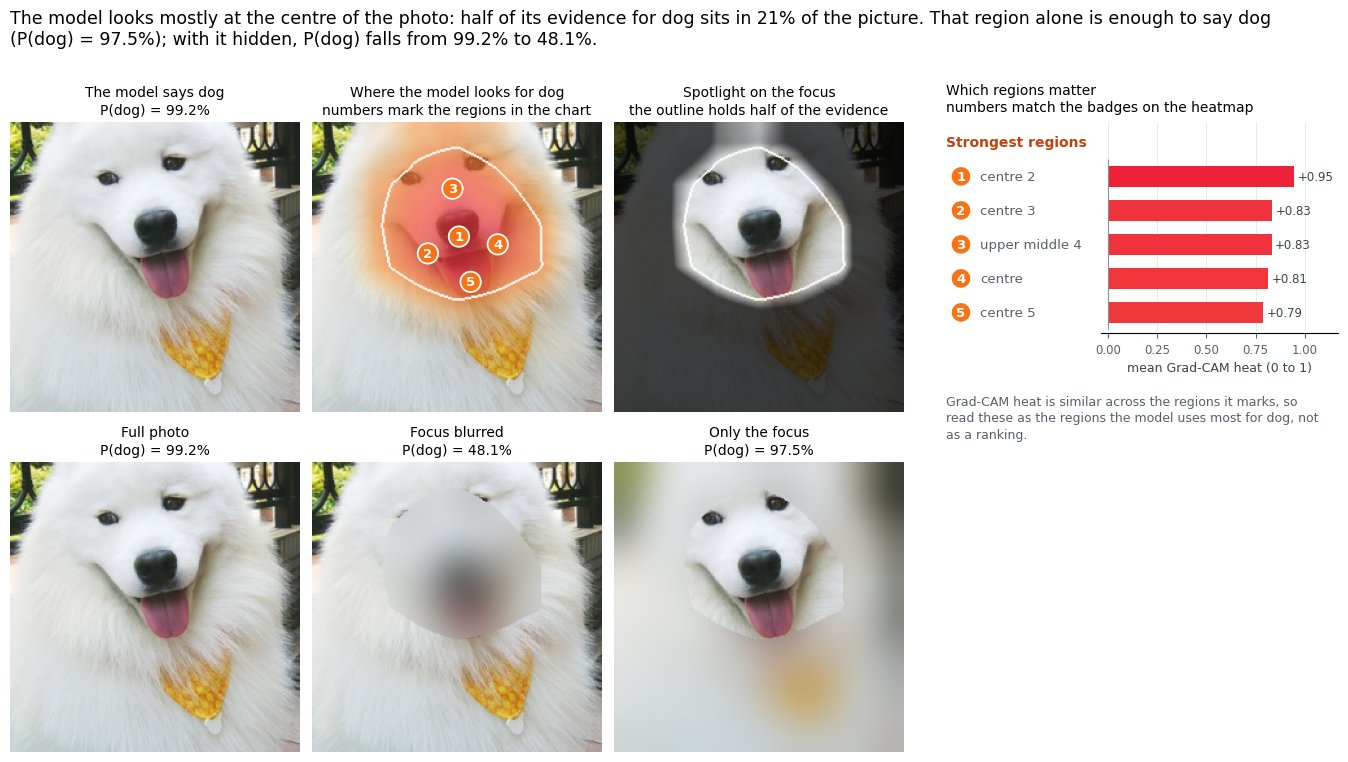

In [4]:
@functools.lru_cache(maxsize=None)
def explain(name, method="gradcam", target=None):
    """Explain one of the loaded photos for its predicted class (or for `target`); answers are cached."""
    require_key()
    options = {"seed": 0, **({"target_class": target} if target else {})}
    return client.explanations.create(model=MODEL, input={feature["name"]: pixels[name]}, method=method, options=options)


for name in ["cat_siamese", "dog_samoyed"]:
    plot_explanation(pixels[name], explain(name), feature=feature)
    plt.show()

Both answers rest on the **face**, and you can still see it through the glow. For the Siamese the
hot spot covers the dark mask between the ears: eyes, nose and muzzle. For the Samoyed it is the
black nose and the mouth, up to the eyes; the white fur, the bandana and the fence stay outside the
outline. The five numbered regions all sit inside the outline, and their bars are about the same
length: Grad-CAM spreads its heat smoothly, so read them as the strongest regions, not a ranking.

The evidence check says how much the face matters. For the Samoyed, blurring it drops P(dog) from
99.2% to 48.1%, a coin toss, while the face alone keeps it at 97.5%: the face carries the decision.
For the Siamese the face alone is enough too (99.5%), but blurring it barely matters (98.8%): the
pointed ears and the rest of the cat outside the outline still say cat. The model has more than one
cue for cats.

## Same photo, two questions

`cat_and_dog.jpg` holds a Siamese on the left and a pug on the right. The model calls it a cat,
but we can ask both *"why cat?"* and *"why dog?"* about the same pixels (`target`). This time
with **LIME**, which blurs random sets of regions and watches how the answer moves; unlike
Grad-CAM it also shows what works *against* a class, in blue.

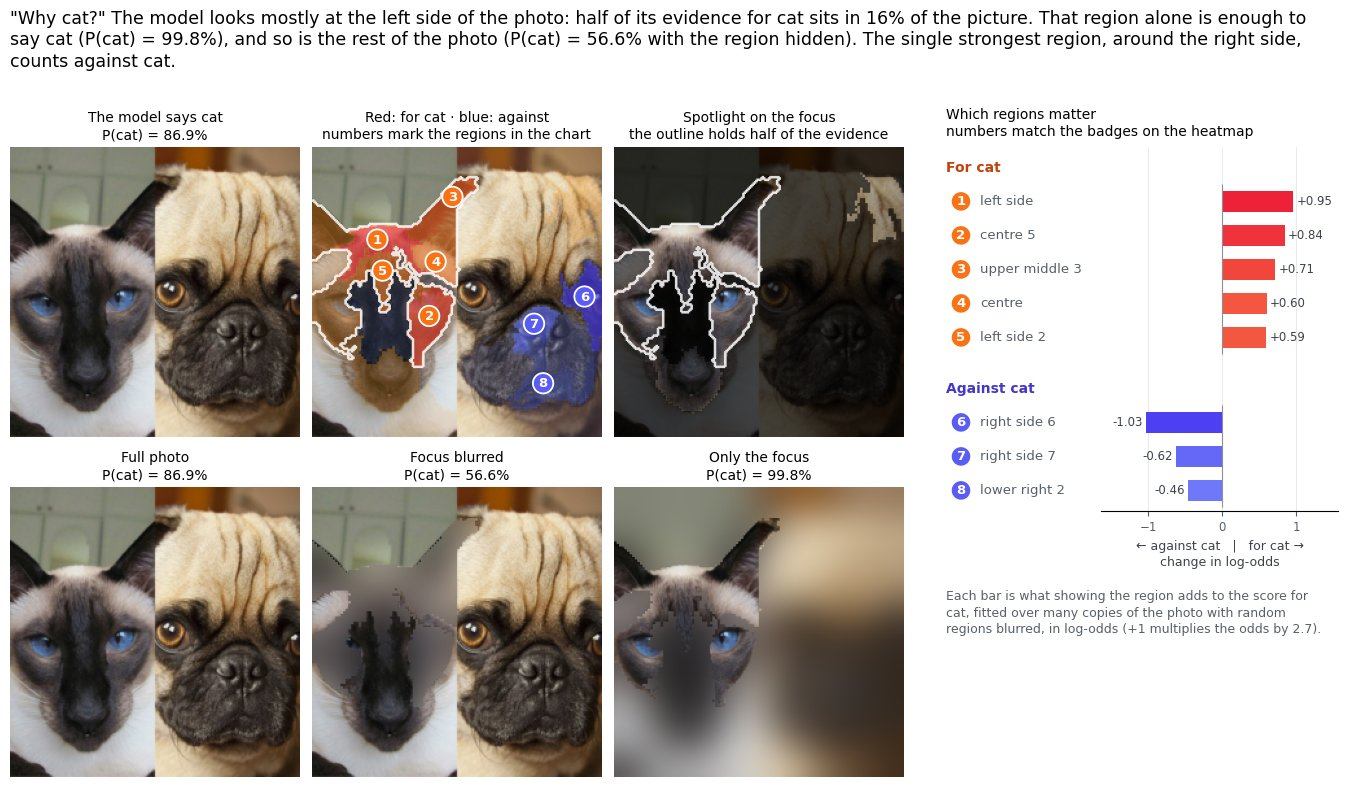

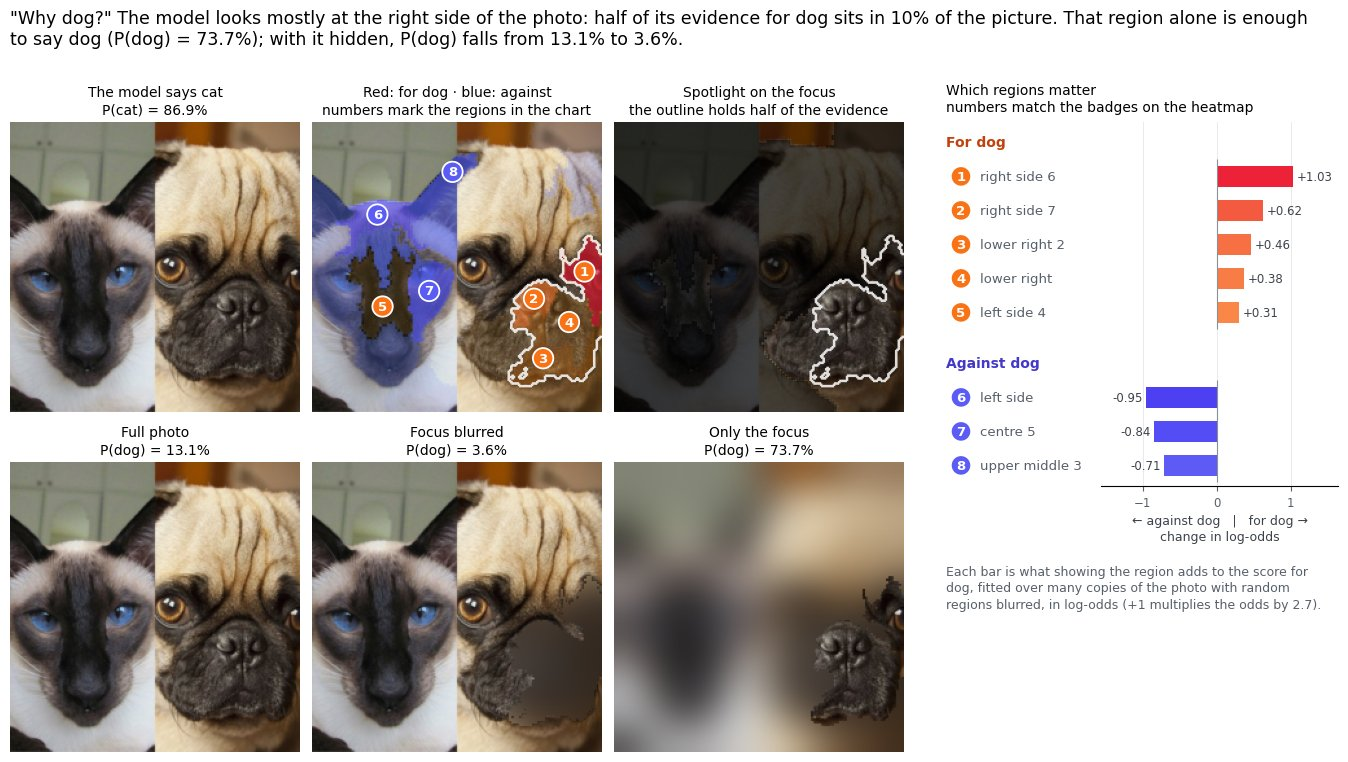

In [5]:
for target in ["cat", "dog"]:
    explanation = explain("cat_and_dog", "lime", target)
    plot_explanation(pixels["cat_and_dog"], explanation, feature=feature,
                     title=f'"Why {target}?"  ' + explanation_summary(explanation))
    plt.show()

*Why cat?* lights up the Siamese on the left (its ears, forehead and cheeks) and paints the pug's
face blue: the pug is evidence *against* cat. *Why dog?* is the mirror image: the pug's muzzle,
jowls and cheek turn red, and the cat's ears and forehead turn blue. The model separates the two
animals instead of reacting to the scene as a whole.

The evidence check is sharpest for the dog: blurring the pug's face takes P(dog) from 13.1% down to
a few percent, and showing only that region raises it to about three in four, so nearly all of the
dog evidence in this photo sits in that one region. One small surprise: in *why dog?* an orange
badge sits on the Siamese's dark muzzle. That dark, flat patch looks a little like a pug's black
face, and the gallery below shows the same muzzle counting *against* cat on the Siamese photo.

## Three methods, one photo

Kaimei has three ways to explain a photo, and they work very differently:

- **Grad-CAM** follows the gradient (one pass, a smooth map, about a second).
- **Occlusion** blurs each region together with its neighbours and measures how far the model's
  confidence falls (one pass per region, a few seconds).
- **LIME** shows the model a few hundred copies of the photo with random sets of regions blurred
  and fits a simple linear model to the answers (the slowest, 20 to 40 seconds).

Occlusion and LIME cut the photo into a few dozen regions ("superpixels" that follow edges and
colours; on a busy server LIME uses fewer, larger ones so it finishes in time) and score them in
**log-odds** of the class: +1 means the region multiplies
the odds by about 2.7. When three different methods point at the same parts of the dog, that is
good evidence the model really uses them.

Grad-CAM: 3 model calls, 0.6 s on the server


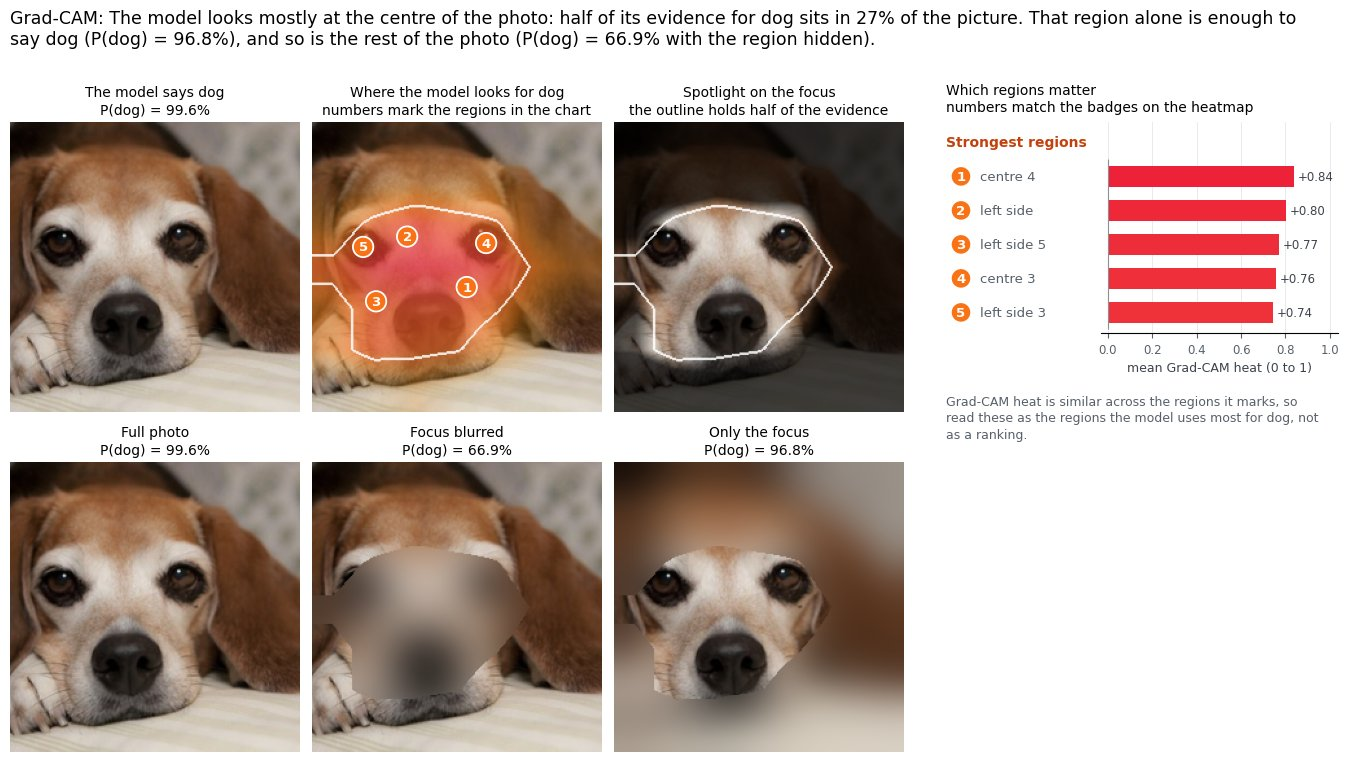

Occlusion: 46 model calls, 3.3 s on the server


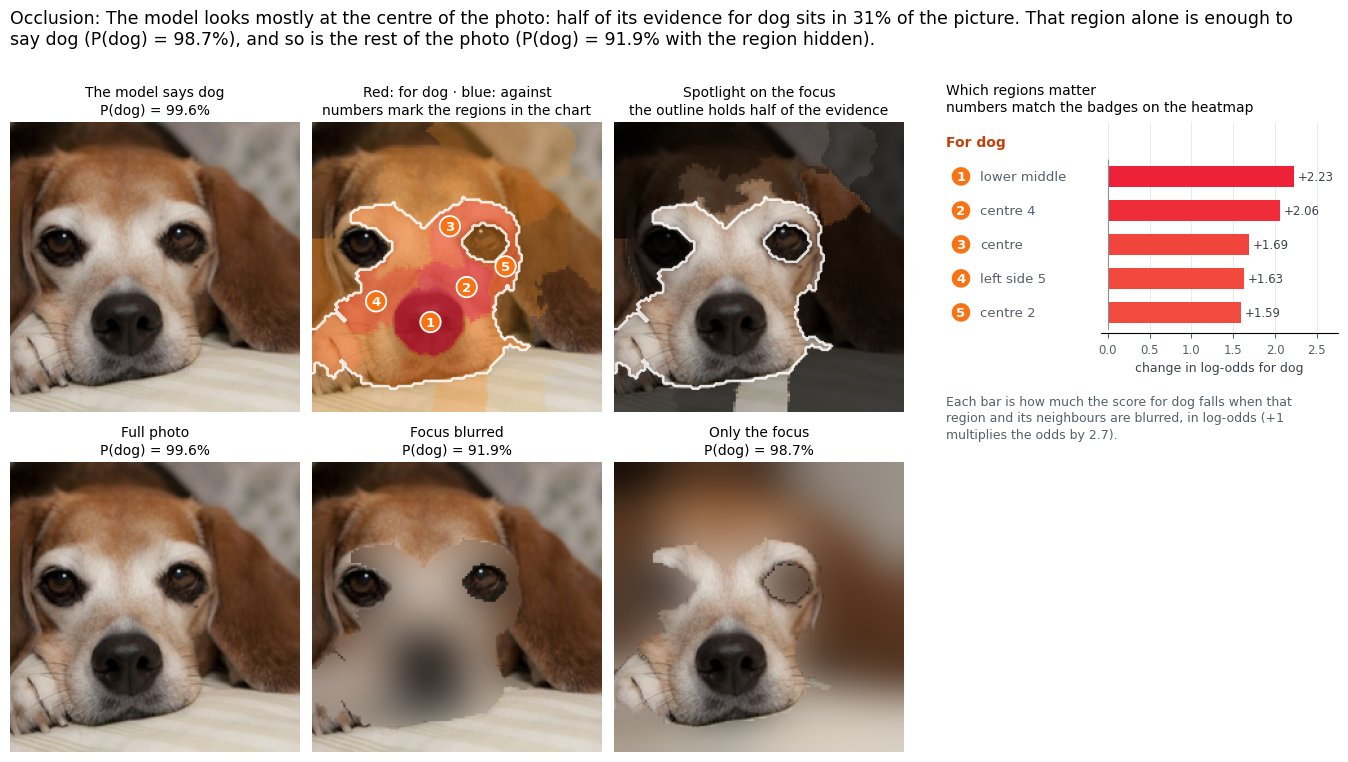

LIME: 259 model calls, 17.3 s on the server


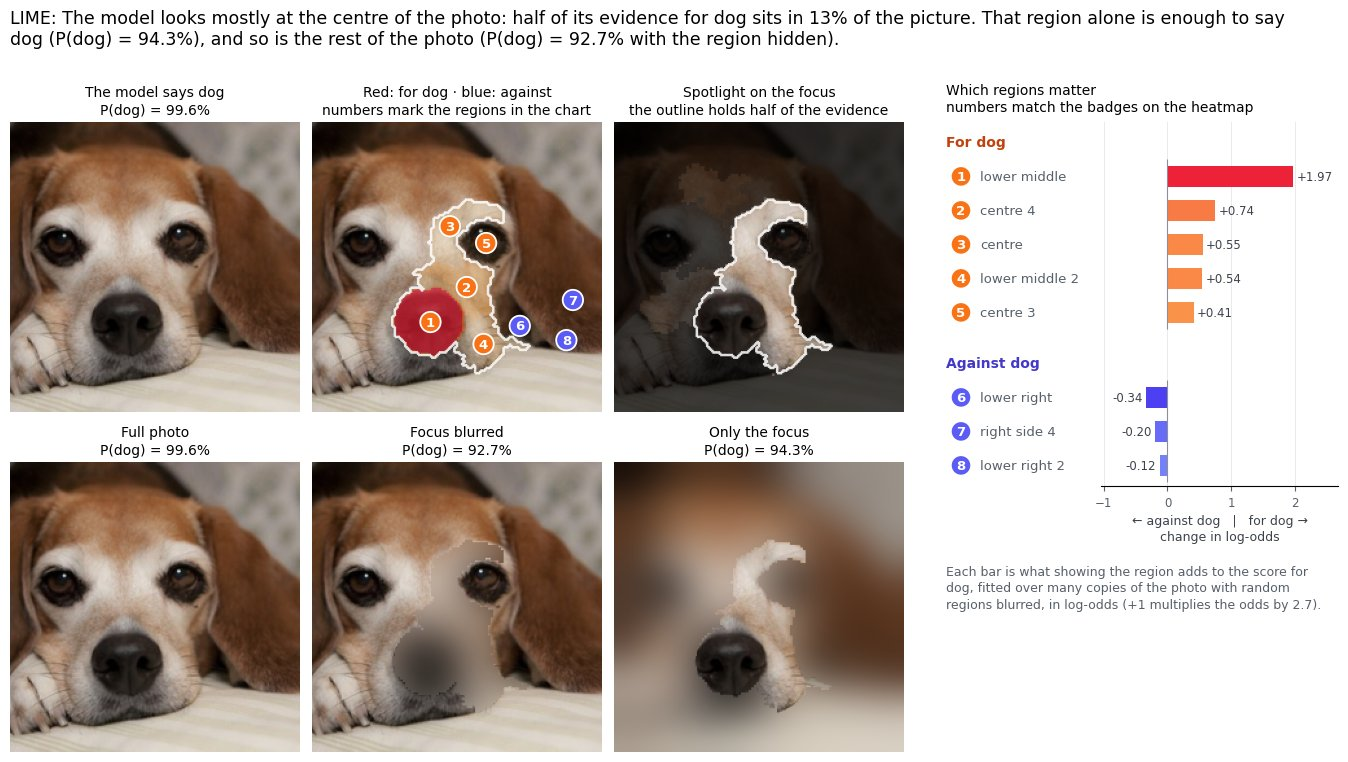

In [6]:
for method, method_name in {"gradcam": "Grad-CAM", "occlusion": "Occlusion", "lime": "LIME"}.items():
    explanation = explain("dog_beagle", method)
    print(f"{method_name}: {explanation.n_evals} model calls, {explanation.latency_ms / 1000:.1f} s on the server")
    plot_explanation(pixels["dog_beagle"], explanation, feature=feature,
                     title=f"{method_name}: " + explanation_summary(explanation))
    plt.show()

All three methods put the beagle's evidence on its **face**, and each adds a detail:

- **Grad-CAM** spreads its heat over the eyes, the brow and the muzzle.
- **Occlusion** finds the nose first: blurring it together with its neighbours costs the model 2.2
  log-odds; the white blaze between the eyes and the cheeks follow.
- **LIME** agrees on the nose by a wide margin (region 1, about +2 log-odds, which on its own
  multiplies the odds of "dog" by about 7), and its focus region is little more than the nose and
  the white blaze.

None of them uses the blanket or the wall behind the dog. The methods do not always agree, though:
occlusion and LIME measure what happens when a region is blurred away, not where the model looks,
so on a photo the model is already sure of, such as the cats above, hiding part of the face can make
it even *more* sure, and occlusion then marks parts of a confident cat's face against cat while
Grad-CAM still lights it up.

## What has the model learned?

All six photos, Grad-CAM on top and LIME below, each explaining the model's own answer. Grad-CAM
shows *where* the model looks; LIME, region by region, shows *which parts* change its mind.

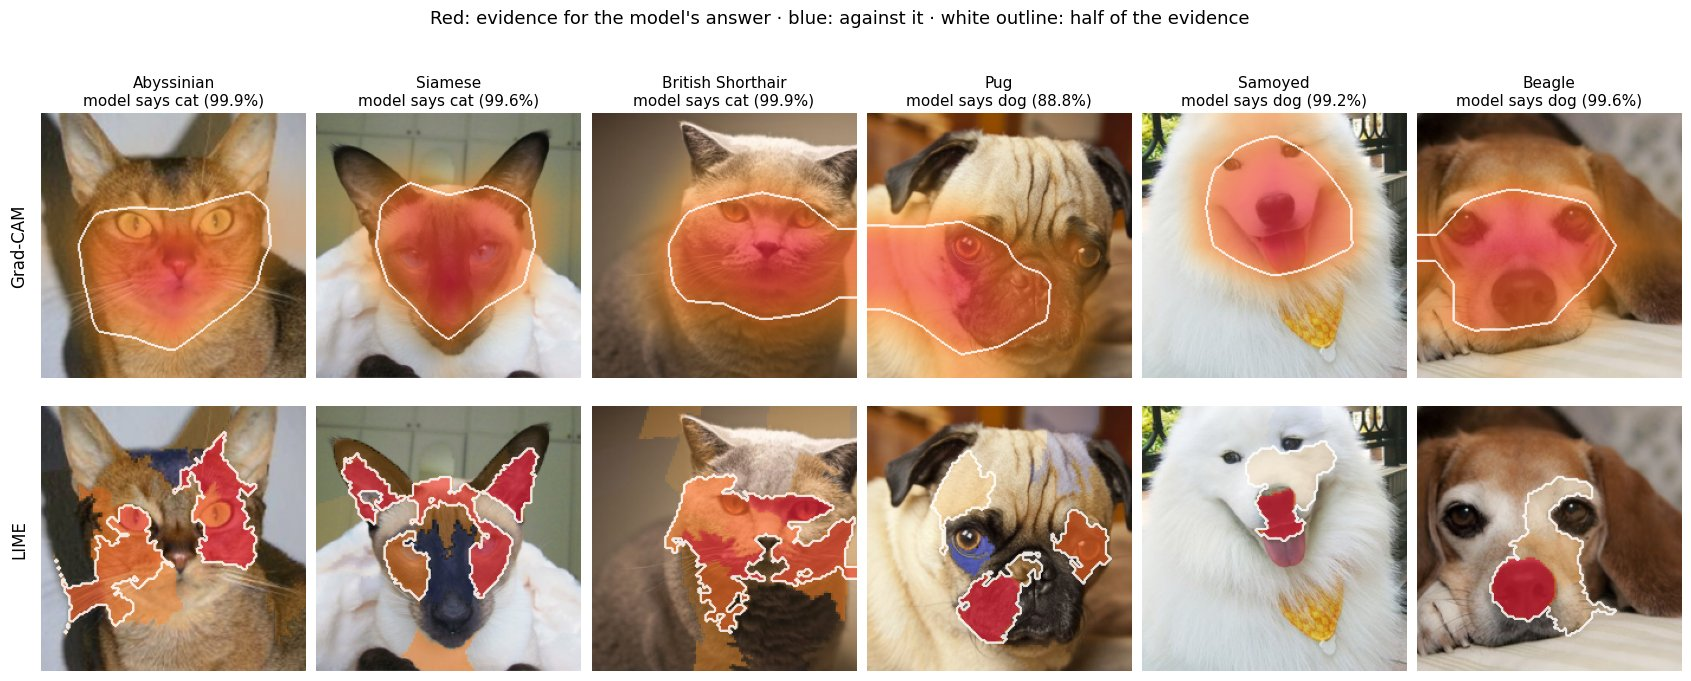

        cat_abyssinian: P(cat) = 99.9%; focus blurred 97.8%, focus alone 99.9%
           cat_siamese: P(cat) = 99.6%; focus blurred 98.8%, focus alone 99.5%
 cat_british_shorthair: P(cat) = 99.9%; focus blurred 97.9%, focus alone 99.9%+
               dog_pug: P(dog) = 88.8%; focus blurred 45.2%, focus alone 48.0%
           dog_samoyed: P(dog) = 99.2%; focus blurred 48.1%, focus alone 97.5%
            dog_beagle: P(dog) = 99.6%; focus blurred 66.9%, focus alone 96.8%


In [7]:
fig, axes = plt.subplots(2, 6, figsize=(17, 6.9))
fig.subplots_adjust(left=0.03, right=0.995, top=0.84, bottom=0.01, wspace=0.04, hspace=0.05)
for column, name in enumerate(NAMES):
    for row, method in enumerate(["gradcam", "lime"]):
        axes[row, column].imshow(render_explanation(pixels[name], explain(name, method), feature=feature))
        axes[row, column].set_axis_off()
    output = explain(name).output
    axes[0, column].set_title(f"{name.split('_', 1)[1].replace('_', ' ').title()}\n"
                              f"model says {output['label']} ({output['probability']:.1%})", fontsize=11)
for row, label in enumerate(["Grad-CAM", "LIME"]):
    axes[row, 0].text(-0.05, 0.5, label, transform=axes[row, 0].transAxes, rotation=90, ha="right", va="center", fontsize=12)
fig.suptitle("Red: evidence for the model's answer · blue: against it · white outline: half of the evidence", fontsize=13)
plt.show()

percent = lambda p: "99.9%+" if p >= 0.9995 else f"{p:.1%}"  # as the figures print it
for name in NAMES:
    evidence = explain(name).options["evidence"]
    print(f"{name:>22}: P({evidence['label']}) = {percent(evidence['full'])}; "
          f"focus blurred {percent(evidence['without_focus'])}, focus alone {percent(evidence['focus_only'])}")

**What to notice**

- **Grad-CAM** puts the hot spot on the **face** in all six photos; the walls, the blankets, the fence
  and the bandana stay outside the outline. The model has learned the features a person would name,
  not the background.
- **LIME** is more specific, and this is where the model's cues show best: on the cats it picks the
  **pointed ears** (the Abyssinian's and the Siamese's) and the **eyes**; on the Samoyed and the
  beagle, the black **nose**, by a wide margin. On the Siamese the dark muzzle even counts slightly
  *against* cat (blue): it is the part of that face that looks most like a dog's, the same black mask
  the pug has in the composite.
- The **pug** is the case worth pausing on. It is the model's least confident answer (88.8% dog).
  Grad-CAM's focus slides to one eye, the cheek and the left edge of the photo, and that region alone
  only gives 48.0% dog; LIME credits the mouth and jowls rather than the nose, and the big round eye
  even counts slightly against dog. A flat-faced breed lacks the long snout the model leans on for
  the other dogs, so this is plausibly where the model is weakest, and the explanation makes that
  visible.
- Blurring the focus hurts the dogs far more than the cats: P(dog) falls to 45.2% for the pug and
  48.1% for the Samoyed, while all three cats stay above 97% without their focus, because the ears
  and fur outside the outline still say cat. (LIME samples at random and adapts its sample count to
  the server's speed, so its numbers can move a little from run to run; Grad-CAM and occlusion are
  exact.)

## Try your own photo

`load_image` accepts a path, bytes, a PIL image or an array, so any photo works.

In [8]:
my_photo = None  # e.g. "C:/photos/my_dog.jpg" or Path.home() / "Pictures" / "cat.jpg"

if my_photo:
    pixels["mine"] = load_image(my_photo, model=model)
    explain.cache_clear()  # forget an earlier "mine"
    plot_explanation(pixels["mine"], explain("mine"), feature=feature)
    plt.show()
else:
    print("Set my_photo to a file path and re-run this cell.")

Set my_photo to a file path and re-run this cell.


## The same thing on the dashboard

Open the `cats-dogs-photos` model on the dashboard and go to its **Explain** tab: the seven
example photos are there as clickable thumbnails, and Grad-CAM, occlusion and LIME draw the same
heatmap, the same numbered badges and the same summary sentence as above, and you can hover a
region in the list to outline it on the photo. `examples/cats_dogs_gradcam.py` trains and
uploads the model and runs these explanations from the command line.